# N0 — Analyse descriptive de la base d'enquête

> ⚠️ **Données synthétiques** — ce notebook s'exécute sur des données générées par `generate_dummy_data.py`. Les valeurs, proportions et graphiques affichés sont aléatoires et ne décrivent aucune population réelle.

| | Fichiers |
|---|---|
| **Entrée** | `data/2_Donnees_nettoyees/immigration_nettoyee.xlsx` (produit par N1) |
| **Sortie** | graphiques uniquement |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df2 = pd.read_excel("../data/2_Donnees_nettoyees/immigration_nettoyee.xlsx")

## Partie 1 — Profil des répondants

Pour chaque variable socio-démographique, le notebook calcule une distribution de fréquences relatives (`value_counts(normalize=True)`) et la représente avec un graphique adapté à sa nature : barres pour les variables nominales, histogramme pour les variables continues, secteurs pour les variables à deux ou trois modalités. Les codes numériques sont traduits en libellés lisibles par des dictionnaires de correspondance.

In [2]:
# Configuration globale pour tous les graphiques ()
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Information générale sur la base
print(f"Nombre total de répondants : {len(df2)}")

print(f"Nombre de pays représentés : {len(df2['Country'].unique())}")

Nombre total de répondants : 5000
Nombre de pays représentés : 11


Ce bloc fixe une configuration graphique commune à toutes les figures (`plt.rcParams` : taille, police, grille), puis affiche deux indicateurs de volumétrie : le nombre de lignes et le nombre de modalités distinctes de `Country`.

### Répartition par pays

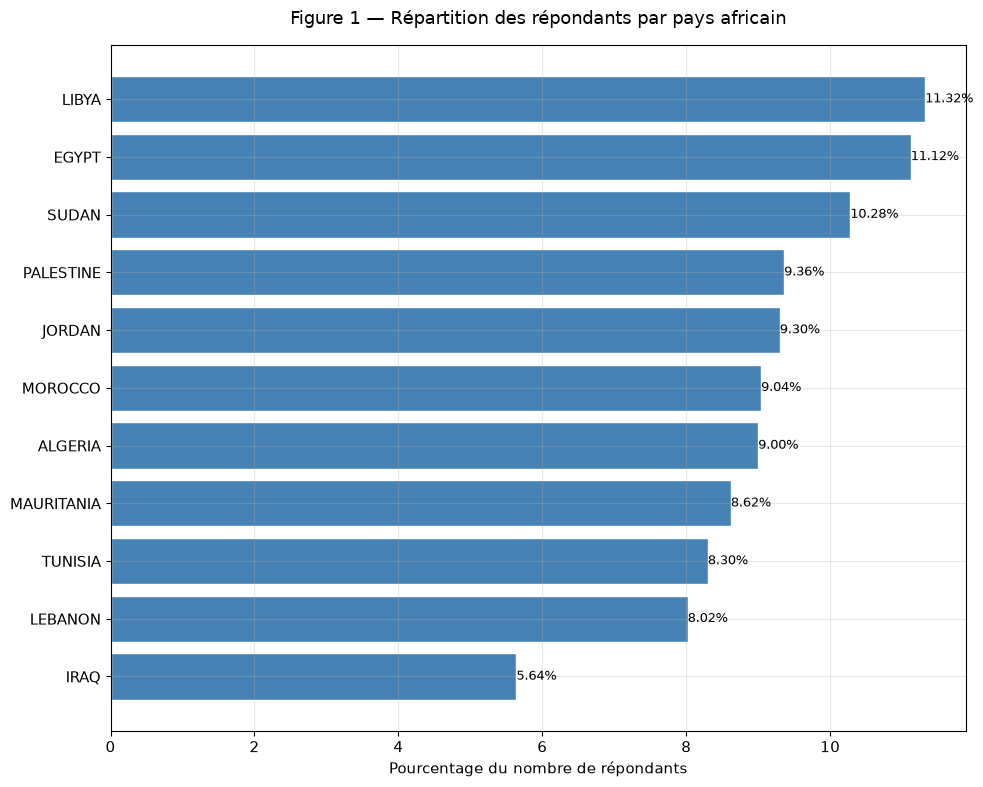

In [3]:
repartition_pays = df2["Country"].value_counts(normalize=True).sort_values() * 100
plt.figure(figsize=(10, 8))
bars = plt.barh(repartition_pays.index, repartition_pays.values, color="steelblue", edgecolor="white")

# Afficher les pourcentages au bout de chaque barre
for i, valeur in enumerate(repartition_pays):
    plt.text(valeur, i, f"{valeur:.2f}%", va="center", fontsize=9)

plt.xlabel("Pourcentage du nombre de répondants")
plt.title("Figure 1 — Répartition des répondants par pays africain", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

Fréquences relatives de `Country` exprimées en %, triées par ordre croissant (`sort_values`) pour que la barre la plus longue apparaisse en haut du graphique horizontal. Chaque barre est annotée de sa valeur avec `plt.text`, en itérant sur la série.

### Distribution de l'âge

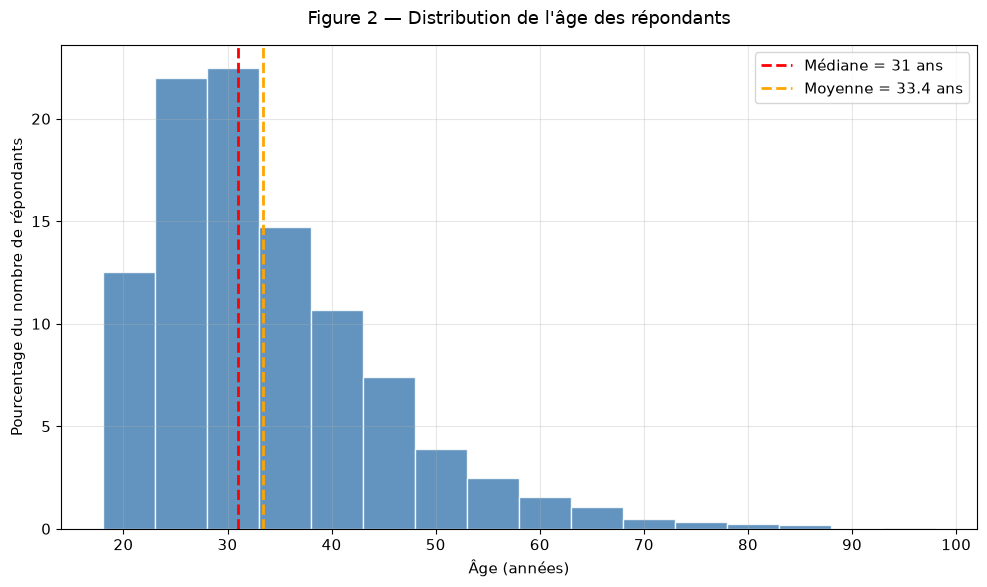

In [4]:
plt.figure(figsize=(10, 6))
poids = np.ones_like(df2["Age"]) / len(df2) * 100
nbr_barre = range(int(df2["Age"].min()), int(df2["Age"].max()), 5)
plt.hist(df2["Age"], bins=nbr_barre, weights=poids, color="steelblue", edgecolor="white", alpha=0.85)

# Lignes de référence : médiane et moyenne
mediane = df2["Age"].median()
moyenne = df2["Age"].mean()
plt.axvline(mediane, color="red", linestyle="--", linewidth=2,label=f"Médiane = {mediane:.0f} ans")
plt.axvline(moyenne, color="orange", linestyle="--", linewidth=2,label=f"Moyenne = {moyenne:.1f} ans")

plt.xlabel("Âge (années)")
plt.ylabel("Pourcentage du nombre de répondants")
plt.title("Figure 2 — Distribution de l'âge des répondants", fontsize=13, pad=15)
plt.legend()
plt.tight_layout()
plt.show()

Histogramme pondéré : le vecteur `weights` (`np.ones_like(...) / len(df2) * 100`) convertit les effectifs en pourcentages, et les classes ont une largeur fixe de 5 ans (`range(min, max, 5)`). Deux droites verticales (`axvline`) matérialisent la médiane et la moyenne : leur écart donne une lecture immédiate de l'asymétrie de la distribution.

### Répartition par genre

2166
2834
Calcul correct


<Figure size 1000x600 with 0 Axes>

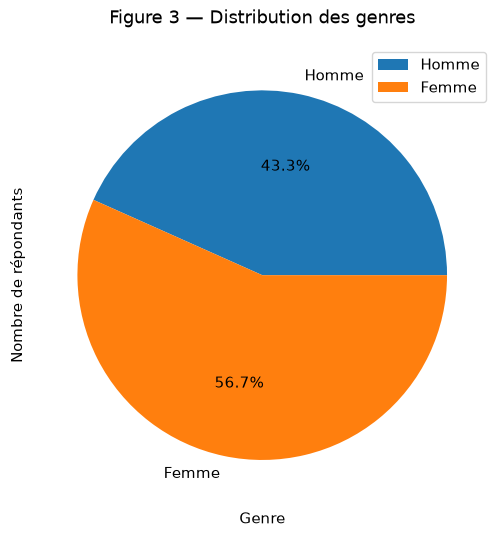

In [5]:
plt.figure(figsize=(10, 6))

# Calcul du total d'homme dans notre base de données
homme = 0
for h in df2["Genderf"] :
  if h == 1 :
    homme += 1

# Calcul du total de femme dans notre base de données déduis grâce à notre variable Homme
femme = len(df2["Genderf"]) - homme

print(homme)
print(femme)

# Vérification de nos données total
if len(df2) == homme + femme :
  print("Calcul correct")

labels = 'Homme', 'Femme'
sizes = [homme, femme]

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels,autopct="%1.1f%%")

plt.xlabel("Genre")
plt.ylabel("Nombre de répondants")
plt.title("Figure 3 — Distribution des genres", fontsize=13, pad=15)
plt.legend()
plt.show()

Le nombre de modalités `1` est compté par une boucle explicite ; l'autre effectif est obtenu par différence, avec un contrôle de cohérence (`len(df2) == homme + femme`) avant le tracé du diagramme en secteurs (`ax.pie`, pourcentages via `autopct`).

### Répartition par statut social

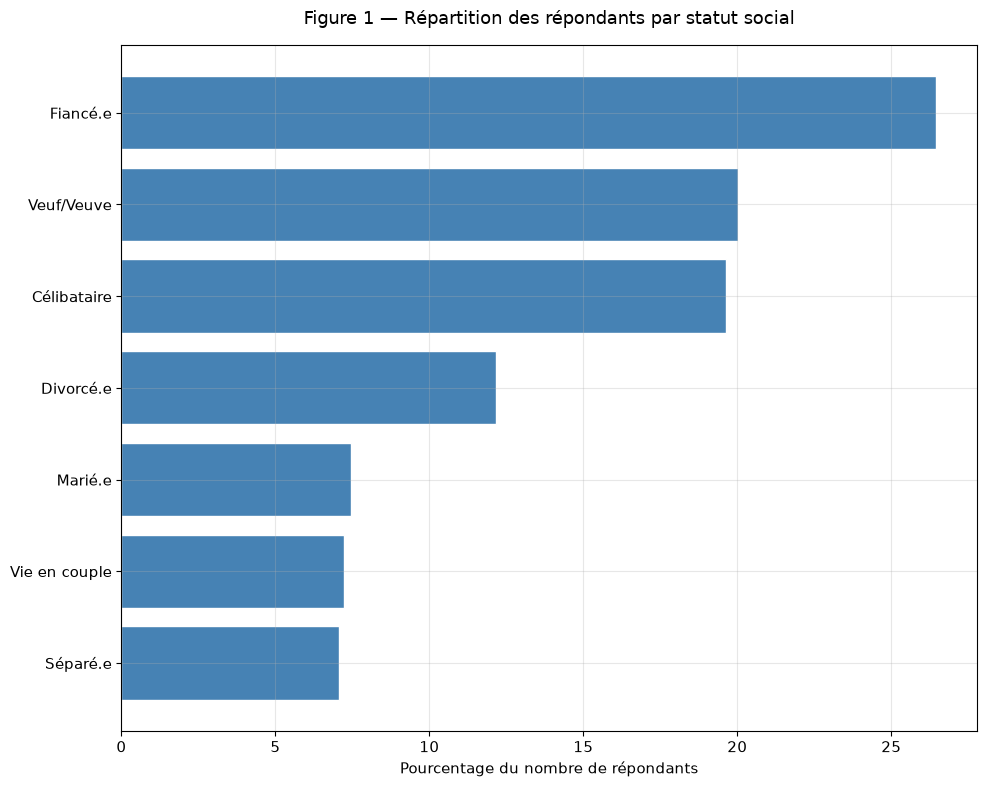

In [6]:
correspondance = {
    1: "Célibataire",
    2: "Vie en couple",
    3: "Fiancé.e",
    4: "Marié.e",
    5: "Divorcé.e",
    6: "Séparé.e",
    7: "Veuf/Veuve"
}

statut_social = df2["Social statusf"].value_counts(normalize=True).sort_values() * 100
statut_social.index = statut_social.index.map(correspondance)
plt.figure(figsize=(10, 8))
bars = plt.barh(statut_social.index, statut_social.values, color="steelblue", edgecolor="white")

plt.xlabel("Pourcentage du nombre de répondants")
plt.title("Figure 1 — Répartition des répondants par statut social", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

Les codes 1 à 7 de `Social statusf` sont remplacés par leurs libellés en appliquant le dictionnaire `correspondance` à l'index de la série (`index.map`), puis représentés en barres horizontales triées.

### Répartition par zone de résidence (`Regionf`)

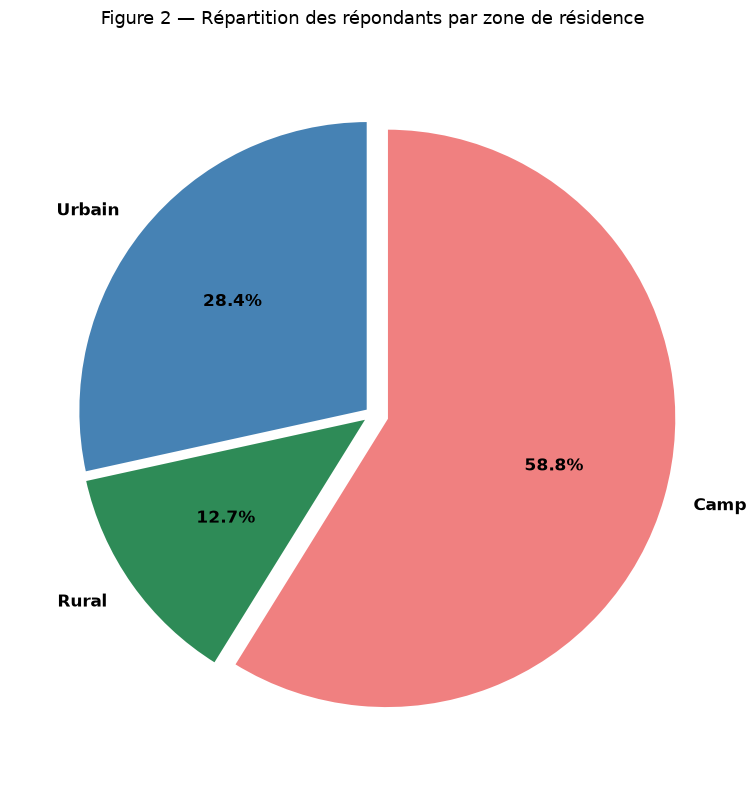

In [7]:
correspondance = {
    1: "Urbain",
    2: "Rural",
    3: "Camp"
}

region = df2["Regionf"].value_counts().sort_index()
region.index = region.index.map(correspondance)

plt.figure(figsize=(8, 8))
couleurs = ["steelblue", "seagreen", "lightcoral"]
explode = [0.02, 0.02, 0.05]

plt.pie(
    region.values,
    labels=region.index,
    autopct="%1.1f%%",
    colors=couleurs,
    startangle=90,
    explode=explode,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12, "fontweight": "bold"}
)

plt.title("Figure 2 — Répartition des répondants par zone de résidence",fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Diagramme en secteurs des trois modalités de `Regionf`. L'ordre des codes est conservé (`sort_index`) pour que chaque couleur reste associée à la même modalité d'un graphique à l'autre ; `explode` et `wedgeprops` séparent visuellement les parts.

### Répartition par niveau d'éducation (`Educationf`)

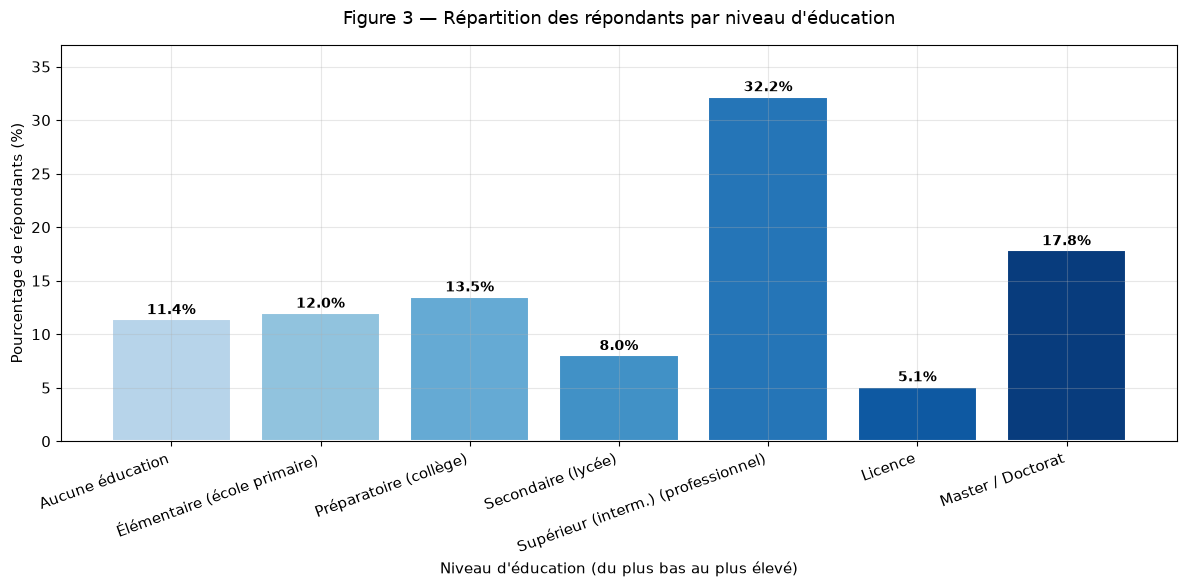

In [8]:
correspondance = {
    1: "Aucune éducation",
    2: "Élémentaire (école primaire)",
    3: "Préparatoire (collège)",
    4: "Secondaire (lycée)",
    5: "Supérieur (interm.) (professionnel)",
    6: "Licence",
    7: "Master / Doctorat"
}

education = df2["Educationf"].value_counts(normalize=True).sort_index() * 100
education.index = education.index.map(correspondance)

# Dégradé de couleur du clair (peu éduqué) au foncé (très éduqué)
import matplotlib.cm as cm
couleurs = cm.Blues(np.linspace(0.3, 0.95, len(education)))

plt.figure(figsize=(12, 6))
bars = plt.bar(education.index, education.values, color=couleurs, edgecolor="white", linewidth=1.5)

# Afficher les pourcentages au-dessus de chaque barre
for bar, valeur in zip(bars, education.values):
    plt.text(bar.get_x() + bar.get_width()/2,bar.get_height() + 0.5,f"{valeur:.1f}%",
             ha="center", fontsize=10, fontweight="bold")

plt.xlabel("Niveau d'éducation (du plus bas au plus élevé)", fontsize=11)
plt.ylabel("Pourcentage de répondants (%)", fontsize=11)
plt.title("Figure 3 — Répartition des répondants par niveau d'éducation", fontsize=13, pad=15)
plt.xticks(rotation=20, ha="right")
plt.ylim(0, max(education.values) * 1.15)  # marge pour les labels
plt.tight_layout()
plt.show()

Variable ordinale : l'ordre naturel des modalités est conservé (`sort_index`) et renforcé par un dégradé de couleurs séquentiel (`cm.Blues`, échantillonné avec `np.linspace`). La limite de l'axe Y est relevée de 15 % (`ylim`) pour laisser la place aux étiquettes au-dessus des barres.

### Répartition par situation professionnelle

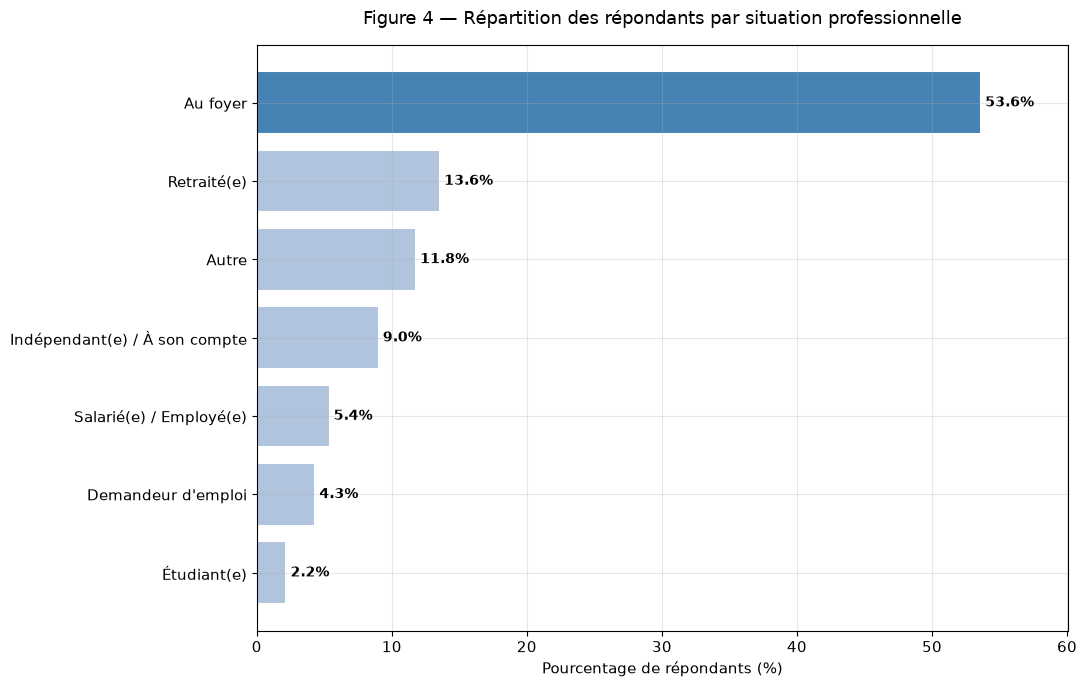

In [9]:
correspondance = {
    1: "Salarié(e) / Employé(e)",
    2: "Indépendant(e) / À son compte",
    3: "Retraité(e)",
    4: "Au foyer",
    5: "Étudiant(e)",
    6: "Demandeur d'emploi",
    7: "Autre"
}

situation_pro = df2["Professional situationf"].value_counts(normalize=True) * 100
situation_pro.index = situation_pro.index.map(correspondance)
situation_pro = situation_pro.sort_values()  # tri pour mettre les plus fréquentes en haut

# Mettre en évidence la catégorie majoritaire en couleur différente
couleurs = ["lightsteelblue"] * len(situation_pro)
couleurs[-1] = "steelblue"

plt.figure(figsize=(11, 7))
bars = plt.barh(situation_pro.index, situation_pro.values,color=couleurs, edgecolor="white", linewidth=1.5)

# Afficher les pourcentages au bout de chaque barre
for bar, valeur in zip(bars, situation_pro.values):
    plt.text(bar.get_width() + 0.3,bar.get_y() + bar.get_height()/2,f"{valeur:.1f}%",va="center", fontsize=10, fontweight="bold")

plt.xlabel("Pourcentage de répondants (%)", fontsize=11)
plt.title("Figure 4 — Répartition des répondants par situation professionnelle",fontsize=13, pad=15)
plt.xlim(0, max(situation_pro.values) * 1.12)  # marge pour les labels
plt.tight_layout()
plt.show()

La modalité la plus fréquente est mise en évidence par une couleur distincte : la série étant triée par ordre croissant, il suffit de modifier le dernier élément de la liste de couleurs (`couleurs[-1]`).

## Partie 2 — Variables d'opinion et variables cibles

Les variables de cette partie sont binaires (0/1). Pour une variable binaire, la moyenne est exactement la proportion de `1` : `mean() * 100` donne donc directement un pourcentage, ce qui permet de comparer plusieurs indicateurs sur une même échelle.

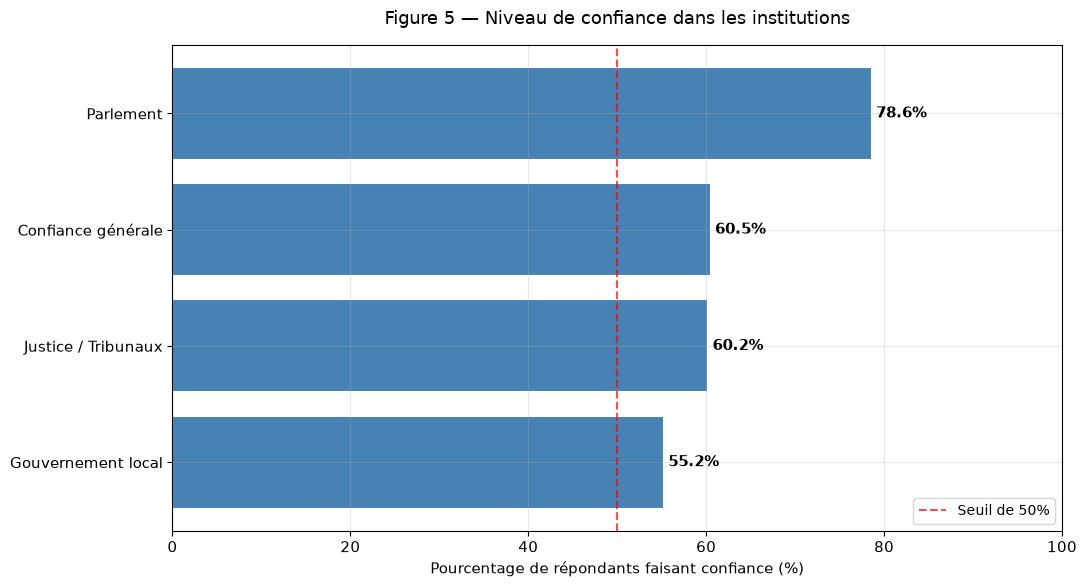

In [10]:
institutions = {
    "Justice / Tribunaux": df2["TrustCourts"].mean() * 100,
    "Parlement": df2["Trust_Parliament"].mean() * 100,
    "Gouvernement local": df2["TrustLocalGovernement"].mean() * 100,
    "Confiance générale": df2["GeneralizedTrsut"].mean() * 100
}

# Trier de la moins à la plus fiable (lecture naturelle de bas en haut)
institutions_triees = dict(sorted(institutions.items(), key=lambda x: x[1]))

plt.figure(figsize=(11, 6))
bars = plt.barh(list(institutions_triees.keys()),list(institutions_triees.values()),color="steelblue", edgecolor="white", linewidth=1.5)

# Pourcentages au bout des barres
for bar, valeur in zip(bars, institutions_triees.values()):
    plt.text(bar.get_width() + 0.5,bar.get_y() + bar.get_height()/2,f"{valeur:.1f}%",
             va="center", fontsize=11, fontweight="bold")

# Ligne de référence à 50%
plt.axvline(50, color="red", linestyle="--", linewidth=1.5, alpha=0.7,label="Seuil de 50%")

plt.xlabel("Pourcentage de répondants faisant confiance (%)", fontsize=11)
plt.title("Figure 5 — Niveau de confiance dans les institutions",fontsize=13, pad=15)
plt.xlim(0, 100)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

Ce bloc construit un dictionnaire `{libellé : proportion}` pour quatre variables de confiance, le trie par valeur (`sorted` avec une clé `lambda`) et l'affiche en barres horizontales. Une ligne de référence à 50 % (`axvline`) sert de repère de lecture.

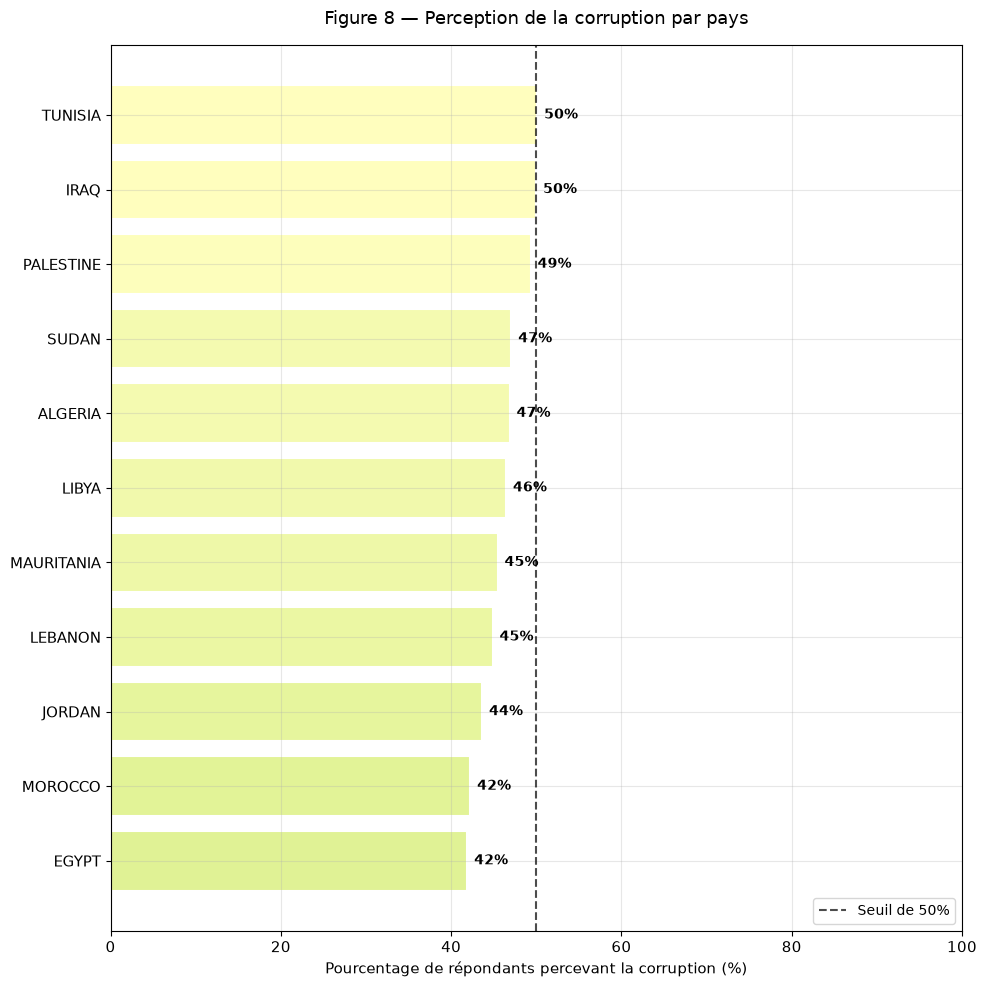

In [11]:
# Pourcentage de répondants percevant de la corruption, par pays
corruption_par_pays = df2.groupby("Country")["Corruption (0  1)"].mean() * 100
corruption_par_pays = corruption_par_pays.sort_values()

# Dégradé vert (peu corrompu) → rouge (très corrompu)
couleurs = plt.cm.RdYlGn_r(corruption_par_pays.values / 100)

plt.figure(figsize=(10, 10))
bars = plt.barh(corruption_par_pays.index, corruption_par_pays.values,color=couleurs, edgecolor="white", linewidth=1.5)

# Pourcentages au bout des barres
for bar, valeur in zip(bars, corruption_par_pays.values):
    plt.text(bar.get_width() + 0.8,bar.get_y() + bar.get_height()/2,f"{valeur:.0f}%",
             va="center", fontsize=10, fontweight="bold")

plt.axvline(50, color="black", linestyle="--", linewidth=1.5, alpha=0.7,
            label="Seuil de 50%")
plt.xlabel("Pourcentage de répondants percevant la corruption (%)", fontsize=11)
plt.title("Figure 8 — Perception de la corruption par pays",fontsize=13, pad=15)
plt.xlim(0, 100)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

Agrégation par groupe : `groupby("Country")[...].mean()` calcule la proportion de `1` dans chaque pays. La couleur de chaque barre est indexée sur sa valeur via la colormap `RdYlGn_r`, ce qui encode l'indicateur deux fois : par la longueur et par la couleur.

### Intention de migrer légalement

**Contrôle du déséquilibre d'échantillonnage.** Les effectifs par pays étant inégaux, les pays les plus représentés pèsent davantage dans une moyenne calculée sur toutes les lignes. Le bloc suivant compare deux estimateurs :

- la **moyenne brute**, calculée sur l'ensemble des répondants (chaque ligne a le même poids) ;
- la **moyenne des moyennes par pays** (`groupby(...).mean().mean()`), où chaque pays a le même poids quel que soit son effectif.

Un écart faible indique que le déséquilibre n'influence pas les indicateurs globaux et que l'on peut travailler sur la base brute ; un écart important justifierait une pondération.

In [12]:
df2["intention_to_migrate_legal"] = df2["intention_to_migrate_legal"].astype("int")

# Moyenne globale NON pondérée (brut)
moyenne_brute = df2["intention_to_migrate_legal"].mean() * 100

# Moyenne globale PONDÉRÉE (chaque pays compte pareil)
moyenne_par_pays = df2.groupby("Country")["intention_to_migrate_legal"].mean() * 100
moyenne_ponderee = moyenne_par_pays.mean()

print(f"Moyenne brute (tous répondants) : {moyenne_brute:.1f} %")
print(f"Moyenne pondérée par pays (équitable) : {moyenne_ponderee:.1f} %")
print(f"\nÉcart entre les deux : {abs(moyenne_brute - moyenne_ponderee):.1f} points")

Moyenne brute (tous répondants) : 31.2 %
Moyenne pondérée par pays (équitable) : 31.1 %

Écart entre les deux : 0.1 points


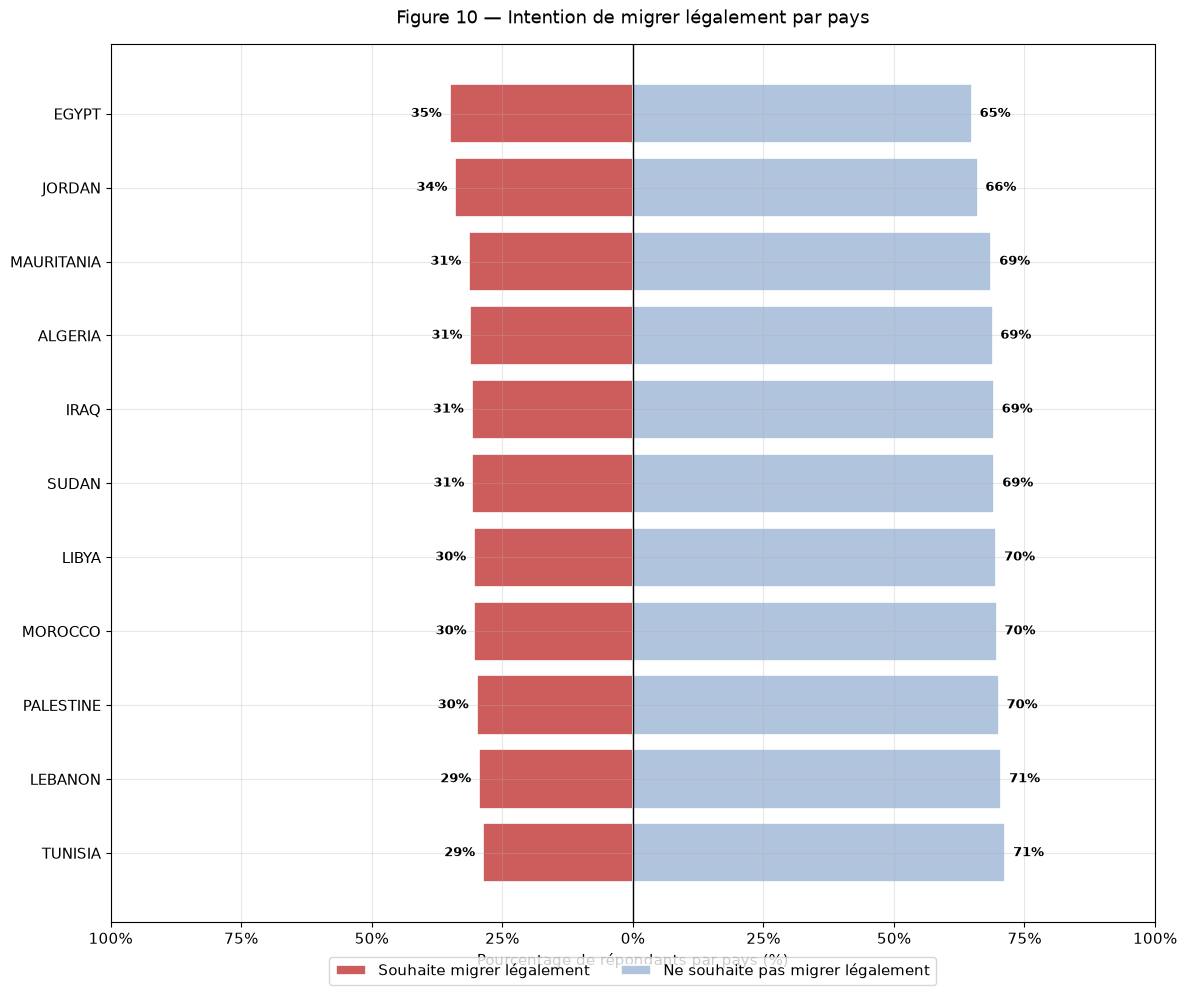

In [13]:
intention_par_pays = df2.groupby("Country")["intention_to_migrate_legal"].value_counts(normalize=True).unstack() * 100
intention_par_pays.columns = ["Non", "Oui"]
intention_par_pays = intention_par_pays.sort_values("Oui", ascending=True)
pays = intention_par_pays.index
oui = intention_par_pays["Oui"].values
non = intention_par_pays["Non"].values
plt.figure(figsize=(12, 10))
plt.barh(pays, -oui, color="indianred", edgecolor="white", linewidth=1.2, label="Souhaite migrer légalement")
plt.barh(pays, non, color="lightsteelblue", edgecolor="white", linewidth=1.2, label="Ne souhaite pas migrer légalement")
for i, (o, n) in enumerate(zip(oui, non)):
    plt.text(-o - 1.5, i, f"{o:.0f}%", va="center", ha="right", fontsize=9, fontweight="bold")
    plt.text(n + 1.5, i, f"{n:.0f}%", va="center", ha="left", fontsize=9, fontweight="bold")
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-100, 100)
plt.xticks([-100, -75, -50, -25, 0, 25, 50, 75, 100], ["100%", "75%", "50%", "25%", "0%", "25%", "50%", "75%", "100%"])
plt.xlabel("Pourcentage de répondants par pays (%)", fontsize=11)
plt.title("Figure 10 — Intention de migrer légalement par pays", fontsize=13, pad=15)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=11)
plt.tight_layout()
plt.show()

Diagramme divergent (« miroir ») : la table de proportions par pays est obtenue par `groupby().value_counts(normalize=True).unstack()`, puis les proportions de `1` sont tracées en valeurs négatives et celles de `0` en valeurs positives, de part et d'autre d'un axe central. Les graduations de l'axe X sont réétiquetées (`plt.xticks`) pour afficher des pourcentages positifs des deux côtés.

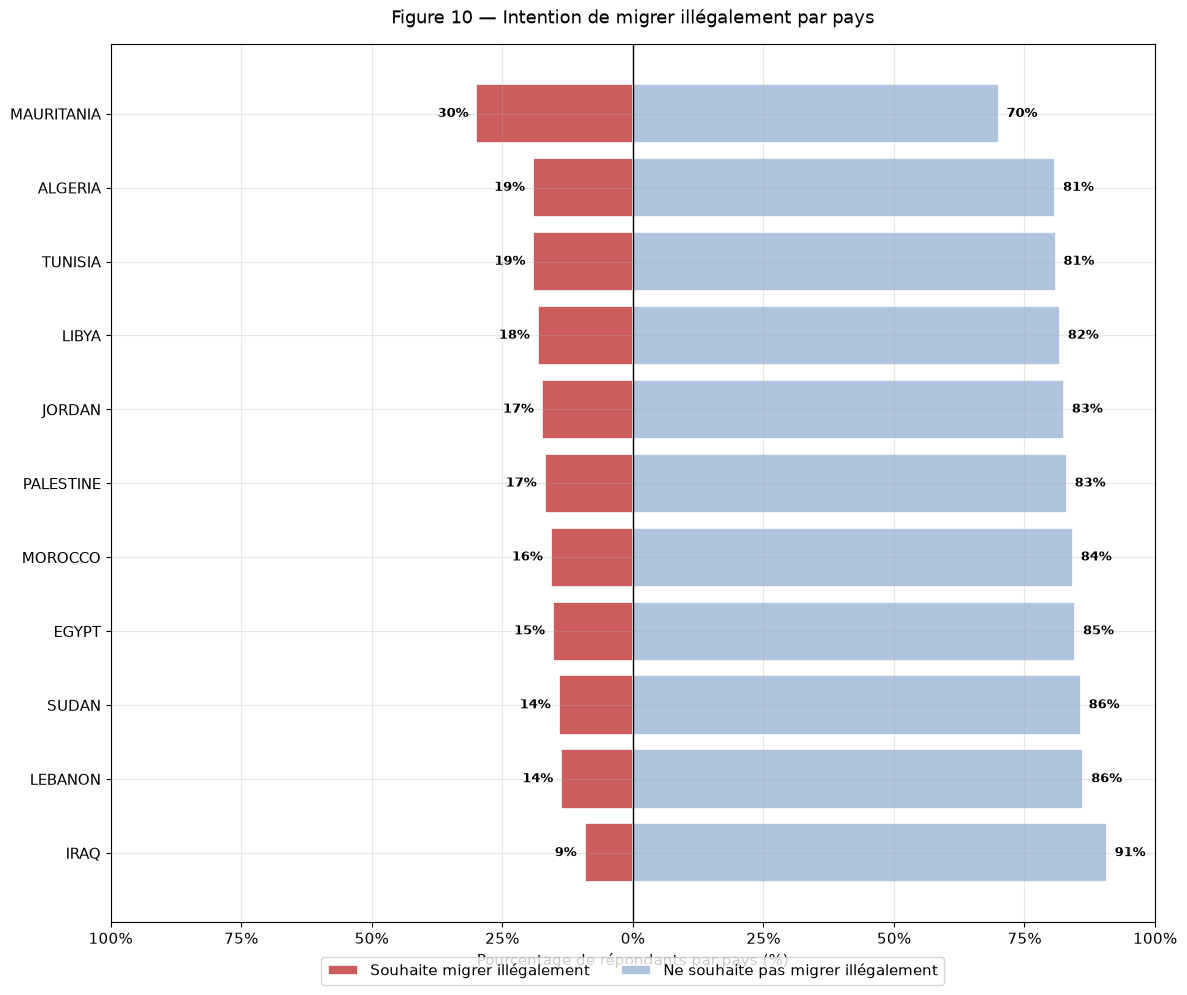

In [14]:
intention_par_pays = df2.groupby("Country")["intention_to_migrate_illegal"].value_counts(normalize=True).unstack() * 100
intention_par_pays = intention_par_pays.reindex(columns=[0, 1], fill_value=0)
intention_par_pays.columns = ["Non", "Oui"]
intention_par_pays = intention_par_pays.sort_values("Oui", ascending=True)
pays = intention_par_pays.index
oui = intention_par_pays["Oui"].values
non = intention_par_pays["Non"].values
plt.figure(figsize=(12, 10))
plt.barh(pays, -oui, color="indianred", edgecolor="white", linewidth=1.2, label="Souhaite migrer illégalement")
plt.barh(pays, non, color="lightsteelblue", edgecolor="white", linewidth=1.2, label="Ne souhaite pas migrer illégalement")
for i, (o, n) in enumerate(zip(oui, non)):
    plt.text(-o - 1.5, i, f"{o:.0f}%", va="center", ha="right", fontsize=9, fontweight="bold")
    plt.text(n + 1.5, i, f"{n:.0f}%", va="center", ha="left", fontsize=9, fontweight="bold")
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-100, 100)
plt.xticks([-100, -75, -50, -25, 0, 25, 50, 75, 100], ["100%", "75%", "50%", "25%", "0%", "25%", "50%", "75%", "100%"])
plt.xlabel("Pourcentage de répondants par pays (%)", fontsize=11)
plt.title("Figure 10 — Intention de migrer illégalement par pays", fontsize=13, pad=15)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=11)
plt.tight_layout()
plt.show()

Même construction pour `intention_to_migrate_illegal`. Le `reindex(columns=[0, 1], fill_value=0)` garantit la présence des deux colonnes même lorsqu'une modalité n'est observée dans aucun groupe, ce qui sécurise le renommage `["Non", "Oui"]`.